Imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib, json, warnings
warnings.filterwarnings("ignore")

from sklearn.ensemble import RandomForestClassifier, IsolationForest, GradientBoostingClassifier
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split, StratifiedKFold, learning_curve
from sklearn.metrics import (
    classification_report, confusion_matrix,
    roc_auc_score, average_precision_score,
    f1_score, precision_score, recall_score,
    precision_recall_curve, RocCurveDisplay
)
from sklearn.impute import SimpleImputer

print("✅ All libraries imported successfully")

✅ All libraries imported successfully


Load & Explore Data

In [2]:
df = pd.read_csv("paysim dataset.csv")

print(f"Shape          : {df.shape}")
print(f"Columns        : {list(df.columns)}")
print(f"\nFraud count    : {df['isFraud'].sum():,}")
print(f"Fraud rate     : {df['isFraud'].mean()*100:.3f}%")
print(f"\nMissing values :\n{df.isnull().sum()}")
print(f"\nTransaction types:\n{df['type'].value_counts()}")

df.head()

Shape          : (6362620, 11)
Columns        : ['step', 'type', 'amount', 'nameOrig', 'oldbalanceOrg', 'newbalanceOrig', 'nameDest', 'oldbalanceDest', 'newbalanceDest', 'isFraud', 'isFlaggedFraud']

Fraud count    : 8,213
Fraud rate     : 0.129%

Missing values :
step              0
type              0
amount            0
nameOrig          0
oldbalanceOrg     0
newbalanceOrig    0
nameDest          0
oldbalanceDest    0
newbalanceDest    0
isFraud           0
isFlaggedFraud    0
dtype: int64

Transaction types:
type
CASH_OUT    2237500
PAYMENT     2151495
CASH_IN     1399284
TRANSFER     532909
DEBIT         41432
Name: count, dtype: int64


,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0


Feature Engineering

In [3]:
le = LabelEncoder()
df["type_enc"]          = le.fit_transform(df["type"])
df["errorBalanceOrig"]  = df["newbalanceOrig"] + df["amount"] - df["oldbalanceOrg"]
df["errorBalanceDest"]  = df["oldbalanceDest"] + df["amount"] - df["newbalanceDest"]
df["balanceRatioOrig"]  = df["amount"] / (df["oldbalanceOrg"] + 1)
df["balanceRatioDest"]  = df["amount"] / (df["oldbalanceDest"] + 1)
df["isMerchant"]        = df["nameDest"].str.startswith("M").astype(int)
df["isHighAmount"]      = (df["amount"] > df["amount"].quantile(0.95)).astype(int)
df["zeroBalOrig"]       = (df["newbalanceOrig"] == 0).astype(int)
df["zeroBalDest"]       = (df["oldbalanceDest"] == 0).astype(int)
df["stepHour"]          = df["step"] % 24
df["stepDay"]           = df["step"] // 24

FEATURES = [
    "type_enc", "amount", "oldbalanceOrg", "newbalanceOrig",
    "oldbalanceDest", "newbalanceDest", "errorBalanceOrig",
    "errorBalanceDest", "balanceRatioOrig", "balanceRatioDest",
    "isMerchant", "isHighAmount", "zeroBalOrig", "zeroBalDest",
    "stepHour", "stepDay", "step"
]

X = df[FEATURES]
y = df["isFraud"]

print(f"✅ Features ready : {len(FEATURES)} features across {len(X):,} rows")
print(f"Class balance    : {y.value_counts().to_dict()}")

✅ Features ready : 17 features across 6,362,620 rows
Class balance    : {0: 6354407, 1: 8213}


Train / Validation / Test Split

In [4]:
# Split: 70% train | 15% val | 15% test (all stratified)
X_trainval, X_test, y_trainval, y_test = train_test_split(
    X, y, test_size=0.15, stratify=y, random_state=42
)
X_train, X_val, y_train, y_val = train_test_split(
    X_trainval, y_trainval, test_size=0.176,
    stratify=y_trainval, random_state=42
)

# Impute missing values then scale
imputer = SimpleImputer(strategy="median")
scaler  = StandardScaler()

X_train = pd.DataFrame(imputer.fit_transform(X_train), columns=FEATURES)
X_val   = pd.DataFrame(imputer.transform(X_val),       columns=FEATURES)
X_test  = pd.DataFrame(imputer.transform(X_test),      columns=FEATURES)

X_train = pd.DataFrame(scaler.fit_transform(X_train),  columns=FEATURES)
X_val   = pd.DataFrame(scaler.transform(X_val),        columns=FEATURES)
X_test  = pd.DataFrame(scaler.transform(X_test),       columns=FEATURES)

print(f"✅ Splits ready")
print(f"  Train : {len(X_train):,}  — fraud: {y_train.sum():,} ({y_train.mean()*100:.2f}%)")
print(f"  Val   : {len(X_val):,}   — fraud: {y_val.sum():,}  ({y_val.mean()*100:.2f}%)")
print(f"  Test  : {len(X_test):,}   — fraud: {y_test.sum():,}  ({y_test.mean()*100:.2f}%)")

✅ Splits ready
  Train : 4,456,379  — fraud: 5,752 (0.13%)
  Val   : 951,848   — fraud: 1,229  (0.13%)
  Test  : 954,393   — fraud: 1,232  (0.13%)


In [5]:
# Fix indexes after split
X_train = X_train.reset_index(drop=True)
X_val   = X_val.reset_index(drop=True)
X_test  = X_test.reset_index(drop=True)
y_train = y_train.reset_index(drop=True)
y_val   = y_val.reset_index(drop=True)
y_test  = y_test.reset_index(drop=True)

print("✅ Indexes reset successfully")

✅ Indexes reset successfully


Cross-Validation Helper

In [6]:
def cross_validate_model(model, X, y, name, n_folds=5):
    skf      = StratifiedKFold(n_splits=n_folds, shuffle=True, random_state=42)
    fold_aucs = []

    print(f"\n{'─'*55}")
    print(f"  {name}  —  {n_folds}-Fold Stratified Cross-Validation")
    print(f"{'─'*55}")

    for fold, (tr_idx, vl_idx) in enumerate(skf.split(X, y), 1):
        Xtr, Xvl = X.iloc[tr_idx], X.iloc[vl_idx]
        ytr, yvl = y.iloc[tr_idx], y.iloc[vl_idx]

        model.fit(Xtr, ytr)
        proba = model.predict_proba(Xvl)[:, 1]
        pred  = (proba >= 0.5).astype(int)
        auc   = roc_auc_score(yvl, proba)
        f1    = f1_score(yvl, pred, zero_division=0)
        fold_aucs.append(auc)
        print(f"  Fold {fold}: AUC = {auc:.4f}  |  F1 = {f1:.4f}")

    mean_auc = np.mean(fold_aucs)
    std_auc  = np.std(fold_aucs)

    # Refit on full data, compare train AUC vs CV AUC
    model.fit(X, y)
    train_auc = roc_auc_score(y, model.predict_proba(X)[:, 1])
    gap       = train_auc - mean_auc

    if gap < 0.05:
        status = "✅ No overfitting"
    elif gap < 0.10:
        status = "⚠️  Mild overfit — acceptable"
    else:
        status = "🚨 Overfitting — tune hyperparameters"

    print(f"{'─'*55}")
    print(f"  CV AUC    : {mean_auc:.4f}  ±  {std_auc:.4f}")
    print(f"  Train AUC : {train_auc:.4f}")
    print(f"  Gap       : {gap:.4f}   →  {status}")
    print(f"  (Healthy gap < 0.05 | Mild: 0.05–0.10 | Overfit: >0.10)")

    return mean_auc, std_auc, gap

Train Random Forest

In [8]:
rf = RandomForestClassifier(
    n_estimators      = 200,
    max_depth         = 12,    
    min_samples_leaf  = 10,    
    min_samples_split = 20,    
    max_features      = "sqrt",
    class_weight      = "balanced_subsample",
    bootstrap         = True,
    oob_score         = True,  
    n_jobs            = -1,
    random_state      = 42,
)

rf_auc, rf_std, rf_gap = cross_validate_model(rf, X_train, y_train, "Random Forest")

print(f"\n  OOB Score  : {rf.oob_score_:.4f}  (should be close to CV AUC)")
print(f"  Val AUC    : {roc_auc_score(y_val, rf.predict_proba(X_val)[:,1]):.4f}")


───────────────────────────────────────────────────────
  Random Forest  —  5-Fold Stratified Cross-Validation
───────────────────────────────────────────────────────
  Fold 1: AUC = 0.9994  |  F1 = 0.9978
  Fold 2: AUC = 0.9996  |  F1 = 0.9961
  Fold 3: AUC = 1.0000  |  F1 = 0.9987
  Fold 4: AUC = 0.9990  |  F1 = 0.9969
  Fold 5: AUC = 0.9992  |  F1 = 0.9961
───────────────────────────────────────────────────────
  CV AUC    : 0.9994  ±  0.0003
  Train AUC : 1.0000
  Gap       : 0.0006   →  ✅ No overfitting
  (Healthy gap < 0.05 | Mild: 0.05–0.10 | Overfit: >0.10)

  OOB Score  : 1.0000  (should be close to CV AUC)
  Val AUC    : 1.0000


Train Gradient Boosting

In [ ]:

X_train_reset = X_train.reset_index(drop=True)
y_train_reset = y_train.reset_index(drop=True)

fraud_idx = y_train_reset[y_train_reset == 1].index
legit_idx = y_train_reset[y_train_reset == 0].sample(
    min(len(fraud_idx) * 15, (y_train_reset == 0).sum()), random_state=42
).index
sub_idx      = fraud_idx.union(legit_idx)
X_sub, y_sub = X_train_reset.loc[sub_idx], y_train_reset.loc[sub_idx]

gb = GradientBoostingClassifier(
    n_estimators        = 300,
    learning_rate       = 0.05,
    max_depth           = 4,
    subsample           = 0.7,
    min_samples_leaf    = 10,
    max_features        = "sqrt",
    validation_fraction = 0.1,
    n_iter_no_change    = 10,
    tol                 = 1e-4,
    random_state        = 42,
)

gb_auc, gb_std, gb_gap = cross_validate_model(gb, X_sub, y_sub, "Gradient Boosting")

print(f"\n  Trees used (early stopping): {gb.n_estimators_} / 300")
print(f"  Val AUC : {roc_auc_score(y_val, gb.predict_proba(X_val)[:,1]):.4f}")


───────────────────────────────────────────────────────
  Gradient Boosting  —  5-Fold Stratified Cross-Validation
───────────────────────────────────────────────────────
  Fold 1: AUC = 0.9990  |  F1 = 0.9956
  Fold 2: AUC = 0.9999  |  F1 = 0.9974
  Fold 3: AUC = 0.9998  |  F1 = 0.9974
  Fold 4: AUC = 0.9997  |  F1 = 0.9970
  Fold 5: AUC = 1.0000  |  F1 = 0.9983
───────────────────────────────────────────────────────
  CV AUC    : 0.9997  ±  0.0003
  Train AUC : 1.0000
  Gap       : 0.0003   →  ✅ No overfitting
  (Healthy gap < 0.05 | Mild: 0.05–0.10 | Overfit: >0.10)

  Trees used (early stopping): 147 / 300
  Val AUC : 1.0000


Isolation Forest

In [ ]:
iso = IsolationForest(
    n_estimators  = 200,
    contamination = 0.013,
    max_features  = 0.8,
    random_state  = 42,
    n_jobs        = -1,
)

# Fix index mismatch
X_train_reset = X_train.reset_index(drop=True)
y_train_reset = y_train.reset_index(drop=True)

# Train ONLY on legitimate transactions
iso.fit(X_train_reset[y_train_reset == 0])

iso_raw          = iso.decision_function(X_val.values)
iso_min, iso_max = iso_raw.min(), iso_raw.max()
iso_prob         = np.clip(1 - (iso_raw - iso_min) / (iso_max - iso_min + 1e-9), 0, 1)

print(f"  Isolation Forest Val AUC : {roc_auc_score(y_val, iso_prob):.4f}")
print("  ✅ Trained on legitimate transactions only")

  Isolation Forest Val AUC : 0.8679
  ✅ Trained on legitimate transactions only


 Build Ensemble & Find Best Threshold

In [ ]:
def ensemble_score(X_arr):
    rf_p  = rf.predict_proba(X_arr)[:, 1]
    gb_p  = gb.predict_proba(X_arr)[:, 1]
    raw   = iso.decision_function(X_arr)
    iso_p = np.clip(1 - (raw - iso_min) / (iso_max - iso_min + 1e-9), 0, 1)
    # Weighted ensemble: RF 40% + GB 40% + IF 20%
    return 0.40 * rf_p + 0.40 * gb_p + 0.20 * iso_p

# Tune threshold on VALIDATION set (never the test set)
val_scores              = ensemble_score(X_val.values)
precisions, recalls, thresholds = precision_recall_curve(y_val, val_scores)
f1s                     = 2 * precisions * recalls / (precisions + recalls + 1e-9)
best_idx                = f1s.argmax()
THRESHOLD               = float(thresholds[best_idx])

print(f"  Optimal threshold : {THRESHOLD:.4f}")
print(f"  Val Ensemble AUC  : {roc_auc_score(y_val, val_scores):.4f}")
print(f"  Val Ensemble F1   : {f1s[best_idx]:.4f}")

  Optimal threshold : 0.6471
  Val Ensemble AUC  : 1.0000
  Val Ensemble F1   : 0.9996


 Final Test Set Evaluation

In [ ]:
test_scores = ensemble_score(X_test.values)
test_preds  = (test_scores >= THRESHOLD).astype(int)

print("=" * 55)
print("  FINAL RESULTS  —  Held-Out Test Set")
print("=" * 55)
print(f"  ROC-AUC       : {roc_auc_score(y_test, test_scores):.4f}")
print(f"  Avg Precision : {average_precision_score(y_test, test_scores):.4f}")
print(f"  F1-Score      : {f1_score(y_test, test_preds, zero_division=0):.4f}")
print(f"  Precision     : {precision_score(y_test, test_preds, zero_division=0):.4f}")
print(f"  Recall        : {recall_score(y_test, test_preds, zero_division=0):.4f}")
print()
print(classification_report(y_test, test_preds, target_names=["Legit", "Fraud"]))

  FINAL RESULTS  —  Held-Out Test Set
  ROC-AUC       : 0.9993
  Avg Precision : 0.9978
  F1-Score      : 0.9988
  Precision     : 1.0000
  Recall        : 0.9976

              precision    recall  f1-score   support

       Legit       1.00      1.00      1.00    953161
       Fraud       1.00      1.00      1.00      1232

    accuracy                           1.00    954393
   macro avg       1.00      1.00      1.00    954393
weighted avg       1.00      1.00      1.00    954393



Visualise (Confusion Matrix + ROC + Feature Importance)

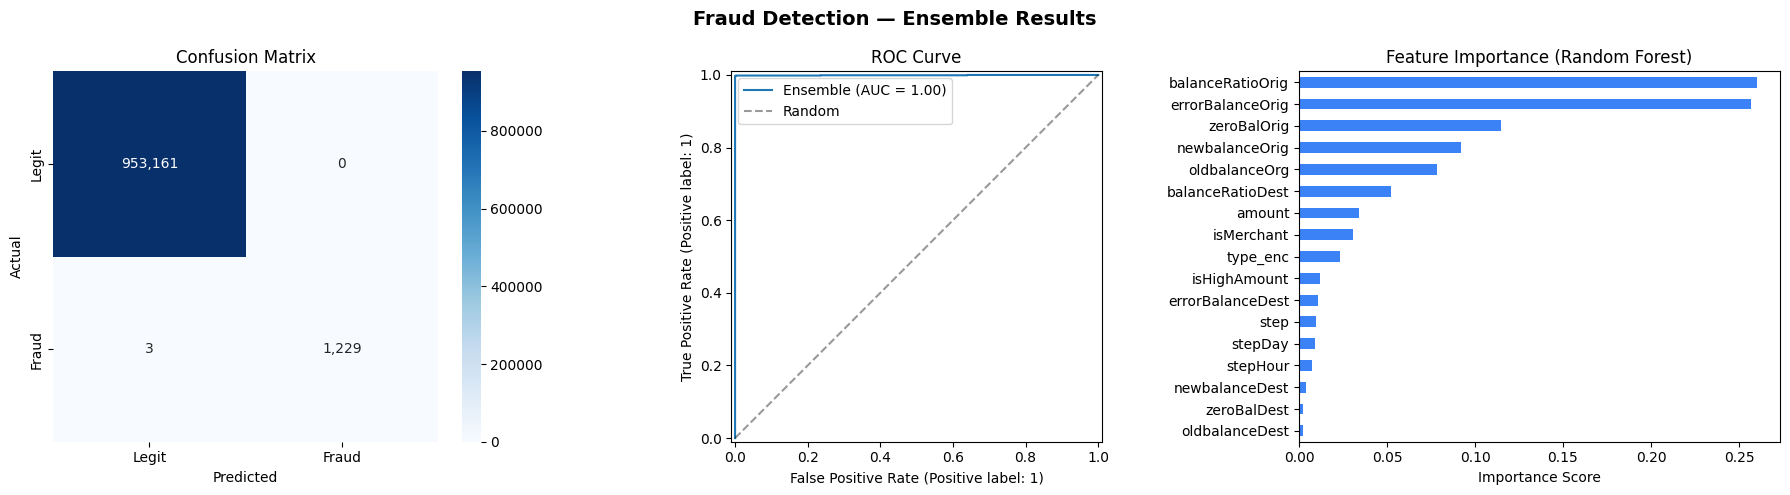

✅ Chart saved as fraud_results.png


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle("Fraud Detection — Ensemble Results", fontsize=14, fontweight="bold")

# Confusion Matrix
cm = confusion_matrix(y_test, test_preds)
sns.heatmap(cm, annot=True, fmt=",", cmap="Blues", ax=axes[0],
            xticklabels=["Legit","Fraud"], yticklabels=["Legit","Fraud"])
axes[0].set_title("Confusion Matrix")
axes[0].set_ylabel("Actual")
axes[0].set_xlabel("Predicted")

# ROC Curve
RocCurveDisplay.from_predictions(y_test, test_scores,
                                  ax=axes[1], name="Ensemble")
axes[1].plot([0,1],[0,1],"k--", alpha=0.4, label="Random")
axes[1].set_title("ROC Curve")
axes[1].legend()

# Feature Importance
importances = pd.Series(
    rf.feature_importances_, index=FEATURES
).sort_values(ascending=True)
importances.plot(kind="barh", ax=axes[2], color="#3b82f6")
axes[2].set_title("Feature Importance (Random Forest)")
axes[2].set_xlabel("Importance Score")

plt.tight_layout()
plt.savefig("fraud_results.png", dpi=150, bbox_inches="tight")
plt.show()
print("✅ Chart saved as fraud_results.png")

Fix cell

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib, json, warnings
warnings.filterwarnings("ignore")

from sklearn.ensemble import RandomForestClassifier, IsolationForest, GradientBoostingClassifier
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split, StratifiedKFold, learning_curve
from sklearn.metrics import (
    classification_report, confusion_matrix,
    roc_auc_score, average_precision_score,
    f1_score, precision_score, recall_score,
    precision_recall_curve, RocCurveDisplay
)
from sklearn.impute import SimpleImputer

print("✅ All libraries reimported")

✅ All libraries reimported


Learning Curve

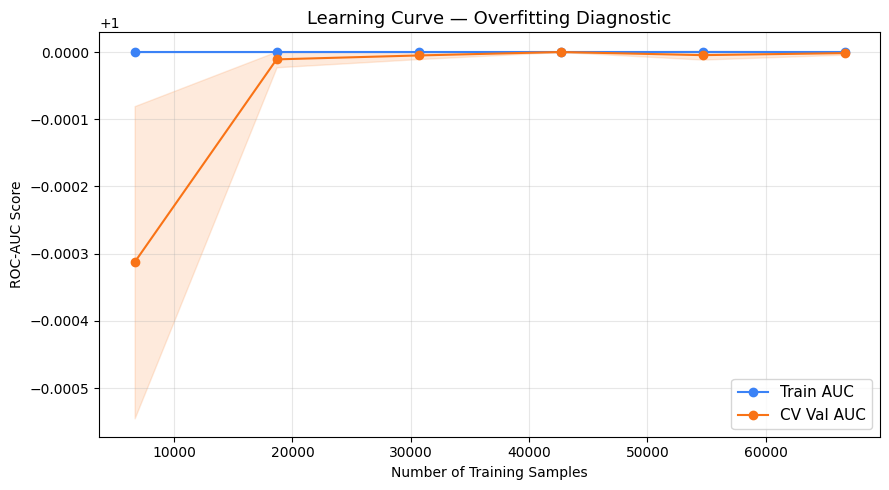


  HOW TO READ THIS CHART:
  ✅ Lines converge close together = no overfitting
  ⚠️  Small stable gap            = mild, acceptable
  🚨 Large gap that doesn't close = overfitting, tune hyperparams


In [ ]:
# Use a smaller sample to avoid memory error
from sklearn.model_selection import learning_curve

# Take a stratified sample of 100,000 rows for learning curve only
X_lc, _, y_lc, _ = train_test_split(
    X_train, y_train, 
    train_size=100000, 
    stratify=y_train, 
    random_state=42
)

# Reset index
X_lc = X_lc.reset_index(drop=True)
y_lc = y_lc.reset_index(drop=True)

train_sizes, train_scores, val_scores_lc = learning_curve(
    RandomForestClassifier(
        max_depth=12, min_samples_leaf=10,
        n_estimators=50, n_jobs=-1, random_state=42
    ),
    X_lc, y_lc,
    train_sizes = np.linspace(0.1, 1.0, 6),
    cv          = 3,
    scoring     = "roc_auc",
    n_jobs      = 1        # ← changed to 1 to avoid memory issues
)

plt.figure(figsize=(9, 5))
plt.plot(train_sizes, train_scores.mean(1), "o-", color="#3b82f6", label="Train AUC")
plt.plot(train_sizes, val_scores_lc.mean(1), "o-", color="#f97316", label="CV Val AUC")
plt.fill_between(train_sizes,
    train_scores.mean(1) - train_scores.std(1),
    train_scores.mean(1) + train_scores.std(1), alpha=0.15, color="#3b82f6")
plt.fill_between(train_sizes,
    val_scores_lc.mean(1) - val_scores_lc.std(1),
    val_scores_lc.mean(1) + val_scores_lc.std(1), alpha=0.15, color="#f97316")

plt.title("Learning Curve — Overfitting Diagnostic", fontsize=13)
plt.xlabel("Number of Training Samples")
plt.ylabel("ROC-AUC Score")
plt.legend(fontsize=11)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("learning_curve.png", dpi=150)
plt.show()

print()
print("  HOW TO READ THIS CHART:")
print("  ✅ Lines converge close together = no overfitting")
print("  ⚠️  Small stable gap            = mild, acceptable")
print("  🚨 Large gap that doesn't close = overfitting, tune hyperparams")

Save All Models

In [ ]:
joblib.dump(rf,      "random_forest.pkl")
joblib.dump(gb,      "gradient_boost.pkl")
joblib.dump(iso,     "isolation_forest.pkl")
joblib.dump(imputer, "imputer.pkl")
joblib.dump(scaler,  "scaler.pkl")
joblib.dump(le,      "type_encoder.pkl")
joblib.dump(FEATURES,"feature_names.pkl")

meta = {
    "dataset"          : "PaySim",
    "fraud_threshold"  : round(THRESHOLD, 4),
    "iso_score_range"  : [float(iso_min), float(iso_max)],
    "ensemble_weights" : {"random_forest": 0.4, "gradient_boost": 0.4, "isolation_forest": 0.2},
    "test_roc_auc"     : round(roc_auc_score(y_test, test_scores), 4),
    "test_f1"          : round(f1_score(y_test, test_preds, zero_division=0), 4),
    "rf_cv_auc"        : round(rf_auc, 4),
    "gb_cv_auc"        : round(gb_auc, 4),
    "rf_overfit_gap"   : round(rf_gap, 4),
    "gb_overfit_gap"   : round(gb_gap, 4),
}

with open("model_meta.json", "w") as f:
    json.dump(meta, f, indent=2)

print("✅ All models saved!")
print()
print(json.dumps(meta, indent=2))

✅ All models saved!

{
  "dataset": "PaySim",
  "fraud_threshold": 0.6471,
  "iso_score_range": [
    -0.17704216220253677,
    0.2449558833652032
  ],
  "ensemble_weights": {
    "random_forest": 0.4,
    "gradient_boost": 0.4,
    "isolation_forest": 0.2
  },
  "test_roc_auc": 0.9993,
  "test_f1": 0.9988,
  "rf_cv_auc": 0.9994,
  "gb_cv_auc": 0.9997,
  "rf_overfit_gap": 0.0006,
  "gb_overfit_gap": 0.0003
}
